# Stock Price Prediction & Market Trend Analysis

## Objective

The objective of this project is to analyze historical stock market data,
identify important trends and patterns, create useful features from
historical stock prices, and develop machine learning models to predict
future stock prices.

The project includes data collection, data cleaning, exploratory data
analysis, visualization, feature engineering, machine learning,
model evaluation, model comparison, and interpretation of results.

## Import Libraries

In [2]:
# Import pandas for data manipulation and analysis
# Import numpy for numerical calculations
# Import matplotlib and seaborn for data visualization
# Import yfinance to collect historical stock market data

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import yfinance as yf

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
# Import the yfinance library to collect stock market data from Yahoo Finance
import yfinance as yf

# Set the stock ticker symbol for Apple Inc.
ticker = "AAPL"

# Download historical AAPL stock data from January 2018 to January 2026
df = yf.download(
    ticker,
    start="2018-01-01",
    end="2026-01-01",
    auto_adjust=False
)

# Display the first 5 rows of the collected dataset
df.head()

[*********************100%***********************]  1 of 1 completed


Price,Adj Close,Close,High,Low,Open,Volume
Ticker,AAPL,AAPL,AAPL,AAPL,AAPL,AAPL
Date,,,,,,
2018-01-02,40.232380,43.064999,43.075001,42.314999,42.540001,102223600
2018-01-03,40.225365,43.057499,43.637501,42.990002,43.132500,118071600
2018-01-04,40.412216,43.257500,43.367500,43.020000,43.134998,89738400
2018-01-05,40.872322,43.750000,43.842499,43.262501,43.360001,94640000
2018-01-08,40.720516,43.587502,43.902500,43.482498,43.587502,82271200


## Data Inspection

In [4]:
# Check the number of rows and columns in the dataset
df.shape

(2011, 6)

In [5]:
# Display the first five rows of the dataset
df.head()

Price,Adj Close,Close,High,Low,Open,Volume
Ticker,AAPL,AAPL,AAPL,AAPL,AAPL,AAPL
Date,,,,,,
2018-01-02,40.232380,43.064999,43.075001,42.314999,42.540001,102223600
2018-01-03,40.225365,43.057499,43.637501,42.990002,43.132500,118071600
2018-01-04,40.412216,43.257500,43.367500,43.020000,43.134998,89738400
2018-01-05,40.872322,43.750000,43.842499,43.262501,43.360001,94640000
2018-01-08,40.720516,43.587502,43.902500,43.482498,43.587502,82271200


In [35]:
# Display the last 5 rows of the dataset to check the most recent records.
df.tail()

Price,Adj Close,Close,High,Low,Open,Volume
Ticker,AAPL,AAPL,AAPL,AAPL,AAPL,AAPL
Date,,,,,,
2025-12-24,273.066711,273.809998,275.429993,272.200012,272.339996,17910600
2025-12-26,272.657837,273.399994,275.369995,272.859985,274.160004,21521800
2025-12-29,273.016876,273.760010,274.359985,272.350006,272.690002,23715200
2025-12-30,272.338684,273.079987,274.079987,272.279999,272.809998,22139600
2025-12-31,271.122009,271.859985,273.679993,271.750000,273.059998,27293600


In [36]:
# Display all column names in the dataset
df.columns

MultiIndex([('Adj Close', 'AAPL'),
            (    'Close', 'AAPL'),
            (     'High', 'AAPL'),
            (      'Low', 'AAPL'),
            (     'Open', 'AAPL'),
            (   'Volume', 'AAPL')],
           names=['Price', 'Ticker'])

In [6]:
# Display the data type of each column in the dataset
df.dtypes

Price      Ticker
Adj Close  AAPL      float64
Close      AAPL      float64
High       AAPL      float64
Low        AAPL      float64
Open       AAPL      float64
Volume     AAPL        int64
dtype: object

In [7]:
# Display summary statistics for the numerical columns in the dataset
df.describe()

Price,Adj Close,Close,High,Low,Open,Volume
Ticker,AAPL,AAPL,AAPL,AAPL,AAPL,AAPL
count,2011.000000,2011.000000,2011.000000,2011.000000,2011.000000,2.011000e+03
mean,135.148500,137.698770,139.089311,136.171116,137.566139,9.442735e+07
std,66.633930,66.321038,66.896689,65.674767,66.256294,5.447156e+07
min,33.707920,35.547501,36.430000,35.500000,35.994999,1.791060e+07
25%,64.213245,66.661251,67.281250,65.807503,66.549999,5.563230e+07
50%,142.552963,145.860001,147.229996,144.110001,145.529999,8.096270e+07
75%,182.466438,184.860001,186.545006,182.695000,184.654999,1.151288e+08
max,285.413116,286.190002,288.619995,283.299988,286.200012,4.265100e+08


In [8]:
# Check if the dataset columns have a MultiIndex (multiple column levels)
if isinstance(df.columns, pd.MultiIndex):
    
# Keep only the first level of the column names
    df.columns = df.columns.get_level_values(0)
    
# Display the first 5 rows after adjusting the column names
df.head()

Price,Adj Close,Close,High,Low,Open,Volume
Date,,,,,,
2018-01-02,40.232380,43.064999,43.075001,42.314999,42.540001,102223600
2018-01-03,40.225365,43.057499,43.637501,42.990002,43.132500,118071600
2018-01-04,40.412216,43.257500,43.367500,43.020000,43.134998,89738400
2018-01-05,40.872322,43.750000,43.842499,43.262501,43.360001,94640000
2018-01-08,40.720516,43.587502,43.902500,43.482498,43.587502,82271200


In [9]:
# Display all column names in the dataset
df.columns

Index(['Adj Close', 'Close', 'High', 'Low', 'Open', 'Volume'], dtype='object', name='Price')

In [10]:
# Check the number of missing (null) values in each column
df.isnull().sum()

Price
Adj Close    0
Close        0
High         0
Low          0
Open         0
Volume       0
dtype: int64

In [11]:
# Remove rows containing missing (null) values from the dataset
df = df.dropna()

In [12]:
# Check the number of missing (null) values in each column
df.isnull().sum()

Price
Adj Close    0
Close        0
High         0
Low          0
Open         0
Volume       0
dtype: int64

In [13]:
# Count the number of duplicate rows in the dataset
df.duplicated().sum()

np.int64(0)

In [14]:
# Convert the index values into datetime format
df.index = pd.to_datetime(df.index)

In [15]:
# Display the index of the dataset, which contains the trading dates
df.index

DatetimeIndex(['2018-01-02', '2018-01-03', '2018-01-04', '2018-01-05',
               '2018-01-08', '2018-01-09', '2018-01-10', '2018-01-11',
               '2018-01-12', '2018-01-16',
               ...
               '2025-12-17', '2025-12-18', '2025-12-19', '2025-12-22',
               '2025-12-23', '2025-12-24', '2025-12-26', '2025-12-29',
               '2025-12-30', '2025-12-31'],
              dtype='datetime64[ns]', name='Date', length=2011, freq=None)

## 1. Historical Closing Price

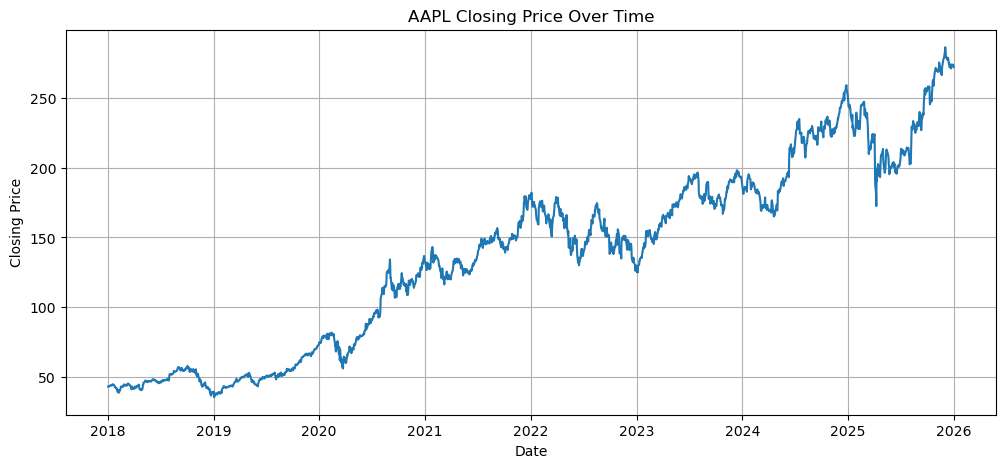

In [16]:
# Create a figure with a width of 12 inches and height of 5 inches
plt.figure(figsize=(12, 5))

# Plot AAPL closing prices over time
plt.plot(df.index, df["Close"])

# Add a title and labels to the chart
plt.title("AAPL Closing Price Over Time")
plt.xlabel("Date")
plt.ylabel("Closing Price")

# Display grid lines for better readability
plt.grid(True)

# Save the chart in the visualizations folder
plt.savefig("visualizations/AAPL_Closing_Price.png")

# Show the plot
plt.show()

##  2.Trading Volume

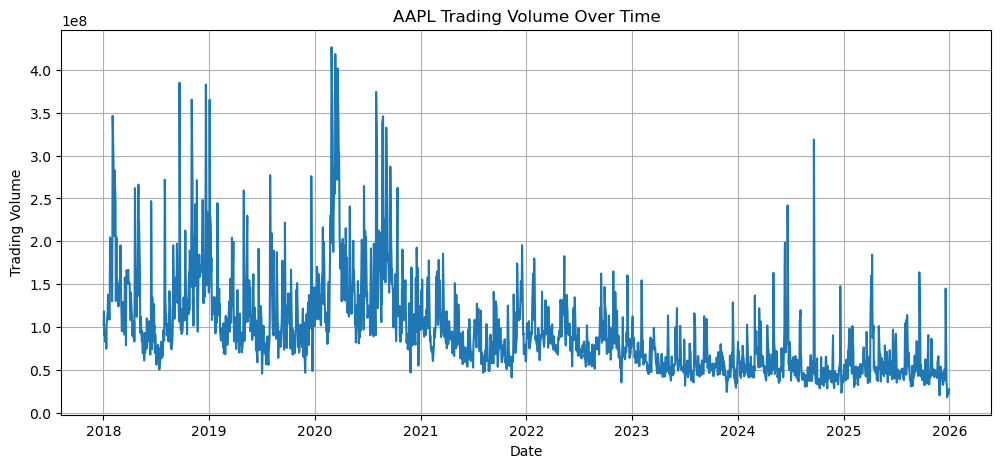

In [17]:
# Create a figure with a width of 12 inches and height of 5 inches
plt.figure(figsize=(12, 5))

# Plot AAPL trading volume over time
plt.plot(df.index, df["Volume"])

# Add a title and labels to the chart
plt.title("AAPL Trading Volume Over Time")
plt.xlabel("Date")
plt.ylabel("Trading Volume")

# Add grid lines for better readability
plt.grid(True)
# Save the chart in the visualizations folder

plt.savefig("visualizations/AAPL_Trading_Volume.png")

# Display the chart
plt.show()

## 3.High vs Low Price

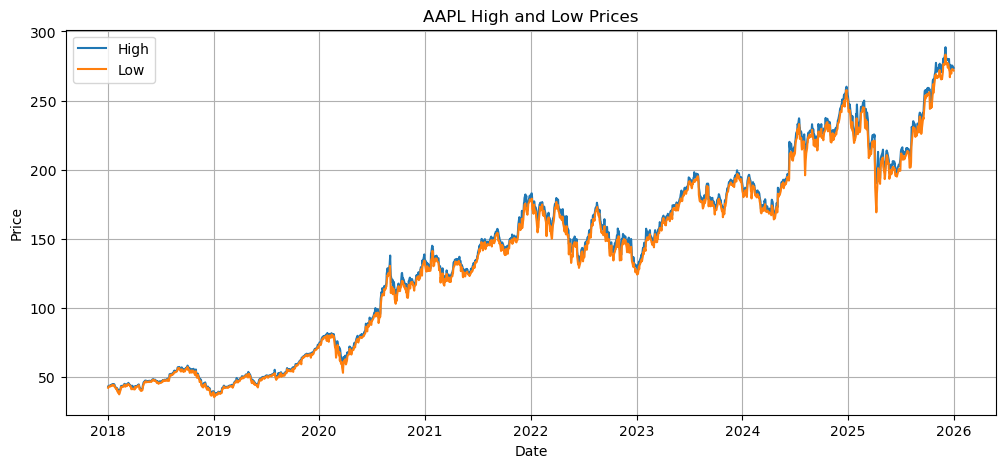

In [18]:
# Create a figure with a width of 12 inches and height of 5 inches
plt.figure(figsize=(12, 5))

# Plot the highest price recorded each day
plt.plot(df.index, df["High"], label="High")

# Plot the lowest price recorded each day
plt.plot(df.index, df["Low"], label="Low")

# Add a title and labels to the chart
plt.title("AAPL High and Low Prices")
plt.xlabel("Date")
plt.ylabel("Price")

# Display the labels for both lines
plt.legend()

# Add grid lines for better readability
plt.grid(True)

# Save the chart in the visualizations folder
plt.savefig("visualizations/AAPL_High_Low_Prices.png")

# Display the chart
plt.show()

## 4.Open vs Close

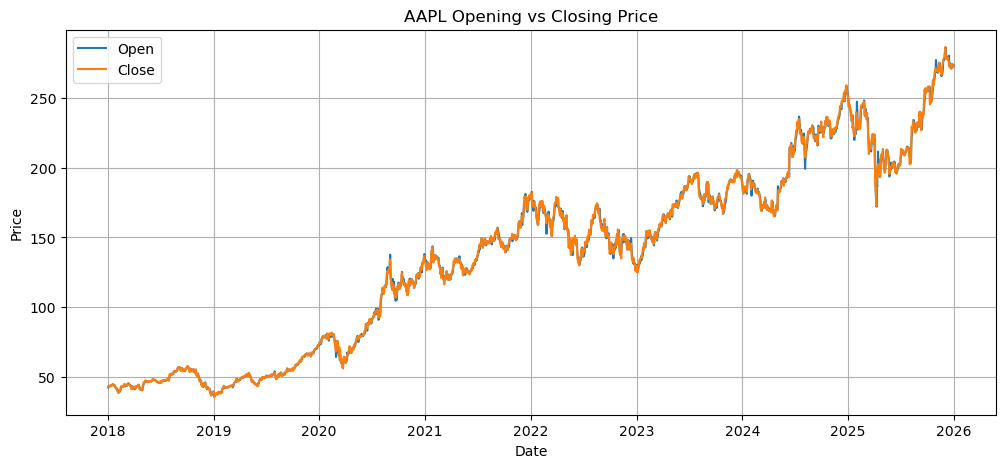

In [19]:
# Create a figure with a width of 12 inches and height of 5 inches
plt.figure(figsize=(12, 5))

# Plot AAPL opening prices over time
plt.plot(df.index, df["Open"], label="Open")

# Plot AAPL closing prices over time
plt.plot(df.index, df["Close"], label="Close")

# Add a title and labels to the chart
plt.title("AAPL Opening vs Closing Price")
plt.xlabel("Date")
plt.ylabel("Price")

# Display the labels for both lines
plt.legend()

# Add grid lines for better readability
plt.grid(True)

# Save the chart in the visualizations folder
plt.savefig("visualizations/AAPL_Open_Close_Prices.png")

# Show the chart
plt.show()

## 5.Daily Price Change

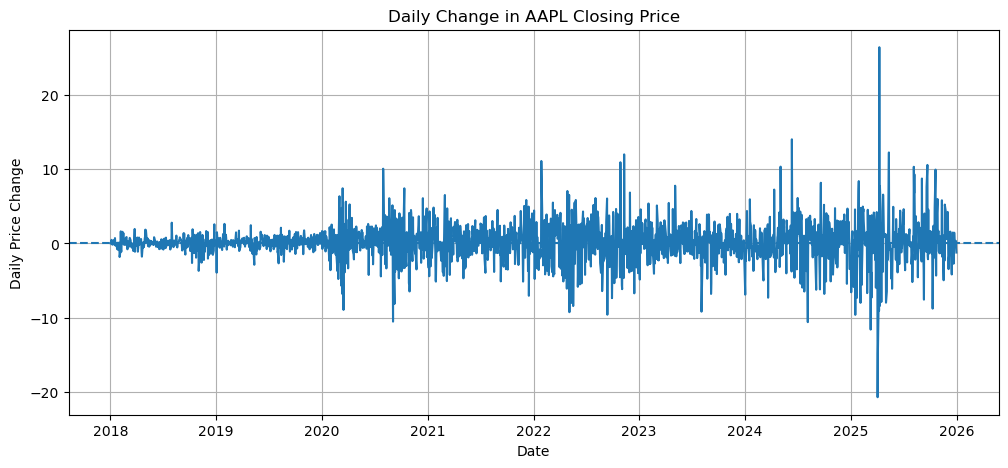

In [20]:
# Calculate the daily change in AAPL's closing price
df["Daily_Change"] = df["Close"].diff()

# Create a figure with a width of 12 inches and height of 5 inches
plt.figure(figsize=(12, 5))

# Plot the daily change in closing price over time
plt.plot(df.index, df["Daily_Change"])

# Add a title and labels to the chart
plt.title("Daily Change in AAPL Closing Price")
plt.xlabel("Date")
plt.ylabel("Daily Price Change")

# Add a horizontal line at zero to compare positive and negative changes
plt.axhline(0, linestyle="--")

# Add grid lines for better readability
plt.grid(True)

# Save the chart in the visualizations folder
plt.savefig("visualizations/AAPL_Daily_Change.png")

# Show the chart
plt.show()

## 6.Correlation Heatmap

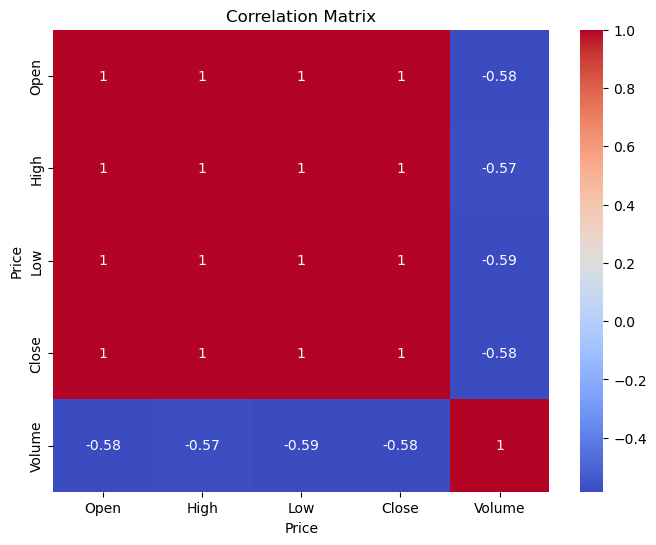

In [22]:
# Create a figure with a width of 8 inches and height of 6 inches
plt.figure(figsize=(8, 6))

# Calculate the correlation between selected stock market features
corr = df[["Open", "High", "Low", "Close", "Volume"]].corr()

# Display the correlation values using a heatmap
sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm"
)

# Add a title to the heatmap
plt.title("Correlation Matrix")

# Save the chart in the visualizations folder
plt.savefig("visualizations/AAPL_Correlation_Heatmap.png")

# Display the chart
plt.show()

In [23]:
# Calculate the 20-day moving average of the closing price
df["MA20"] = df["Close"].rolling(window=20).mean()

# Calculate the 50-day moving average of the closing price
df["MA50"] = df["Close"].rolling(window=50).mean()

In [24]:
# Display the last 5 rows of the closing price and moving averages
df[["Close", "MA20", "MA50"]].tail()

Price,Close,MA20,MA50
Date,,,
2025-12-24,273.809998,277.151999,271.046599
2025-12-26,273.399994,276.944499,271.527799
2025-12-29,273.760010,276.689999,272.053999
2025-12-30,273.079987,276.188998,272.469799
2025-12-31,271.859985,275.472498,272.662199


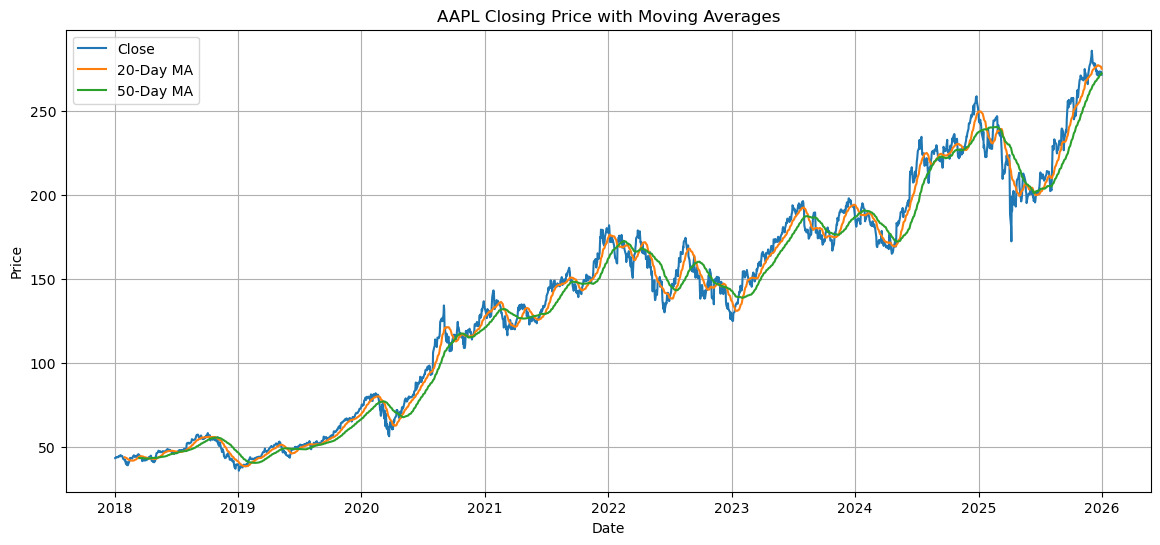

In [25]:
# Create a figure with a width of 14 inches and height of 6 inches
plt.figure(figsize=(14, 6))

# Plot the AAPL closing price
plt.plot(df.index, df["Close"], label="Close")

# Plot the 20-day moving average
plt.plot(df.index, df["MA20"], label="20-Day MA")


# Plot the 50-day moving average
plt.plot(df.index, df["MA50"], label="50-Day MA")

# Add a title and labels to the chart
plt.title("AAPL Closing Price with Moving Averages")
plt.xlabel("Date")
plt.ylabel("Price")

# Display the labels for each line
plt.legend()

# Add grid lines for better readability
plt.grid(True)

# Save the chart in the visualizations folder
plt.savefig("visualizations/AAPL_Moving_Averages.png")

# Display the chart
plt.show()

In [26]:
# Calculate the difference between the highest and lowest price of the day
df["Price_Range"] = df["High"] - df["Low"]

In [27]:
# Display the first 5 rows of the dataset
df.head()

Price,Adj Close,Close,High,Low,Open,Volume,Daily_Change,MA20,MA50,Price_Range
Date,,,,,,,,,,
2018-01-02,40.232380,43.064999,43.075001,42.314999,42.540001,102223600,NaN,NaN,NaN,0.760002
2018-01-03,40.225365,43.057499,43.637501,42.990002,43.132500,118071600,-0.007500,NaN,NaN,0.647499
2018-01-04,40.412216,43.257500,43.367500,43.020000,43.134998,89738400,0.200001,NaN,NaN,0.347500
2018-01-05,40.872322,43.750000,43.842499,43.262501,43.360001,94640000,0.492500,NaN,NaN,0.579998
2018-01-08,40.720516,43.587502,43.902500,43.482498,43.587502,82271200,-0.162498,NaN,NaN,0.420002


In [28]:
# Create the Target column using the next day's closing price
df["Target"] = df["Close"].shift(-1)

In [29]:
# Display the first 5 rows of the Close price and Target columns
df[["Close", "Target"]].head()

Price,Close,Target
Date,,
2018-01-02,43.064999,43.057499
2018-01-03,43.057499,43.257500
2018-01-04,43.257500,43.750000
2018-01-05,43.750000,43.587502
2018-01-08,43.587502,43.582500


In [30]:
# Remove all rows that contain missing (null) values
df = df.dropna()

In [31]:
# Check the number of missing (null) values in each column
df.isnull().sum()

Price
Adj Close       0
Close           0
High            0
Low             0
Open            0
Volume          0
Daily_Change    0
MA20            0
MA50            0
Price_Range     0
Target          0
dtype: int64

In [32]:
# Define the input features used for stock price prediction
features = [
    "Open",
    "High",
    "Low",
    "Volume",
    "MA20",
    "MA50",
    "Daily_Change",
    "Price_Range"
]

# Create X using the selected input features
X = df[features]

# Create y using the target variable
y = df["Target"]

In [33]:
# Display the first 5 rows of the input features
X.head()

Price,Open,High,Low,Volume,MA20,MA50,Daily_Change,Price_Range
Date,,,,,,,,
2018-03-14,45.080002,45.130001,44.452499,117473600,43.949625,43.08015,-0.382500,0.677502
2018-03-15,44.625000,45.060001,44.517502,90975200,44.090625,43.11210,0.052498,0.542500
2018-03-16,44.662498,44.779999,44.404999,157618800,44.153500,43.14105,-0.157497,0.375000
2018-03-19,44.330002,44.367500,43.415001,133787200,44.189375,43.15240,-0.680000,0.952499
2018-03-20,43.810001,44.200001,43.735001,78597600,44.231750,43.15360,-0.014999,0.465000


In [34]:
# Display the first 5 values of the target variable
y.head()

Date
2018-03-14    44.662498
2018-03-15    44.505001
2018-03-16    43.825001
2018-03-19    43.810001
2018-03-20    42.817501
Name: Target, dtype: float64

In [35]:
# Calculate the index where 80% of the data ends
split_index = int(len(df) * 0.8)

# Use the first 80% of the data for training
# Use the remaining 20% of the data for testing
X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

# Display the size of the training and testing datasets
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (1568, 8)
Testing data: (393, 8)


In [36]:
# Create a Linear Regression model
linear_model = LinearRegression()

# Train the Linear Regression model using the training data
linear_model.fit(X_train, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [37]:
# Use the trained Linear Regression model to predict stock prices for the test data
linear_predictions = linear_model.predict(X_test)

In [38]:
# Calculate the Mean Absolute Error (MAE) for Linear Regression
linear_mae = mean_absolute_error(
    y_test,
    linear_predictions
)

# Calculate the Root Mean Squared Error (RMSE) for Linear Regression
linear_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        linear_predictions
    )
)

# Calculate the R-squared (R²) score for Linear Regression
linear_r2 = r2_score(
    y_test,
    linear_predictions
)

# Display the Linear Regression evaluation results
print("Linear Regression Results")
print("-------------------------")
print("MAE :", linear_mae)
print("RMSE:", linear_rmse)
print("R²  :", linear_r2)

Linear Regression Results
-------------------------
MAE : 2.868904514837506
RMSE: 4.069189226533012
R²  : 0.9669263103369108


In [40]:
# Create a Random Forest Regression model with 100 decision trees
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

# Train the Random Forest model using the training data
rf_model.fit(X_train, y_train)

,n_estimators,100
,criterion,'squared_error'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [41]:
# Use the trained Random Forest model to predict stock prices for the test data
rf_predictions = rf_model.predict(X_test)

In [42]:
# Calculate the Mean Absolute Error (MAE) for the Random Forest model
rf_mae = mean_absolute_error(
    y_test,
    rf_predictions
)

# Calculate the Root Mean Squared Error (RMSE) for the Random Forest model
rf_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        rf_predictions
    )
)

# Calculate the R-squared (R²) score for the Random Forest model
rf_r2 = r2_score(
    y_test,
    rf_predictions
)

# Display the Random Forest evaluation results
print("Random Forest Results")
print("---------------------")
print("MAE :", rf_mae)
print("RMSE:", rf_rmse)
print("R²  :", rf_r2)

Random Forest Results
---------------------
MAE : 38.27612091064453
RMSE: 44.16987990014533
R²  : -2.8969004529254065


In [43]:
# Create a DataFrame to compare the performance of both models
results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Random Forest"
    ],
    
# Add Mean Absolute Error (MAE) for both models   
    "MAE": [
        linear_mae,
        rf_mae
    ],

# Add Root Mean Squared Error (RMSE) for both models
    "RMSE": [
        linear_rmse,
        rf_rmse
    ],

# Add R-squared (R²) score for both models
    "R2": [
        linear_r2,
        rf_r2
    ]
})

# Display the model comparison results
results

,Model,MAE,RMSE,R2
0,Linear Regression,2.868905,4.069189,0.966926
1,Random Forest,38.276121,44.169880,-2.896900


In [44]:
# Compare the RMSE values of both models
# The model with the lower RMSE is considered better-performing
if rf_rmse < linear_rmse:
    best_model = "Random Forest"
else:
    best_model = "Linear Regression"

# Display the better-performing model
print("Better-performing model based on RMSE:", best_model)

Better-performing model based on RMSE: Linear Regression


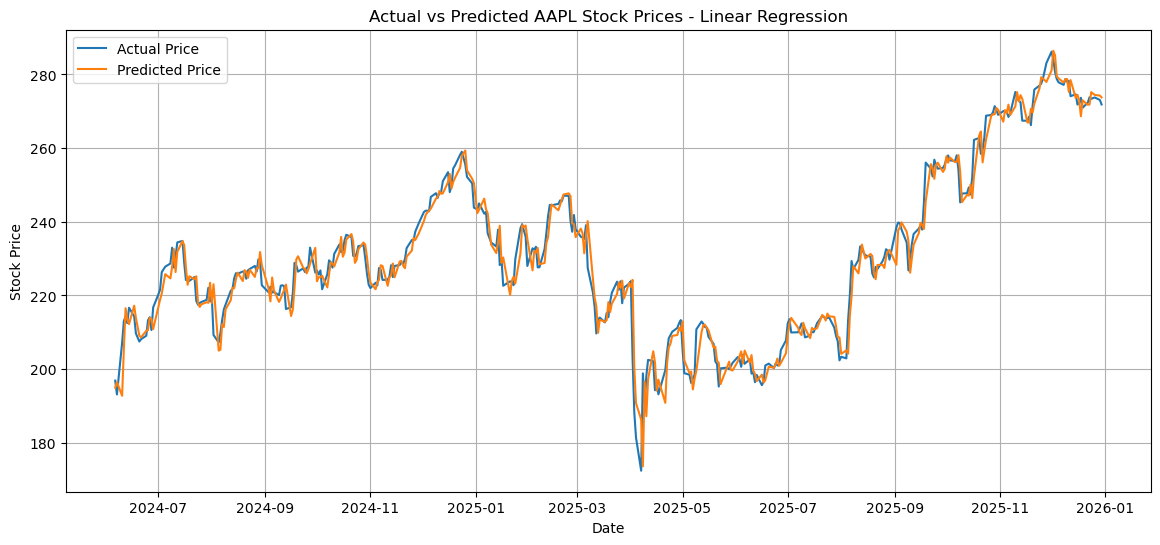

In [45]:
import matplotlib.pyplot as plt

# Generate predictions using Linear Regression
linear_predictions = linear_model.predict(X_test)

# Actual vs Predicted graph
plt.figure(figsize=(14, 6))

plt.plot(y_test.index, y_test, label="Actual Price")
plt.plot(y_test.index, linear_predictions, label="Predicted Price")

plt.title("Actual vs Predicted AAPL Stock Prices - Linear Regression")
plt.xlabel("Date")
plt.ylabel("Stock Price")
plt.legend()
plt.grid(True)
# Save the chart in the visualizations folder
plt.savefig("visualizations/AAPL_Actual_vs_Predicted.png")

plt.show()

In [46]:
# Create a DataFrame containing the actual and predicted stock prices
prediction_df = pd.DataFrame({
    "Actual_Price": y_test,
    "Predicted_Price": linear_predictions
})

# Display the first 10 prediction results
prediction_df.head(10)

,Actual_Price,Predicted_Price
Date,,
2024-06-06,196.889999,194.955965
2024-06-07,193.119995,196.464121
2024-06-10,207.149994,192.762447
2024-06-11,213.070007,205.335526
2024-06-12,214.240005,216.543092
2024-06-13,212.490005,213.539490
2024-06-14,216.669998,212.222712
2024-06-17,214.289993,217.236005
2024-06-18,209.679993,213.885047


In [47]:
# Calculate the prediction error by subtracting the predicted price from the actual price
prediction_df["Error"] = (
    prediction_df["Actual_Price"]
    - prediction_df["Predicted_Price"]
)

In [48]:
# Display the first 10 rows of the prediction results
prediction_df.head(10)

,Actual_Price,Predicted_Price,Error
Date,,,
2024-06-06,196.889999,194.955965,1.934034
2024-06-07,193.119995,196.464121,-3.344126
2024-06-10,207.149994,192.762447,14.387547
2024-06-11,213.070007,205.335526,7.734481
2024-06-12,214.240005,216.543092,-2.303087
2024-06-13,212.490005,213.539490,-1.049485
2024-06-14,216.669998,212.222712,4.447286
2024-06-17,214.289993,217.236005,-2.946012
2024-06-18,209.679993,213.885047,-4.205055


In [49]:
# Create a DataFrame containing each feature and its Random Forest importance
importance = pd.DataFrame({
    "Feature": features,
    "Importance": rf_model.feature_importances_
})

# Sort the features from highest importance to lowest importance
importance = importance.sort_values(
    by="Importance",
    ascending=False
)

# Display the feature importance values
importance

,Feature,Importance
5,MA50,0.295565
4,MA20,0.270293
1,High,0.179024
2,Low,0.170812
0,Open,0.083474
6,Daily_Change,0.000417
3,Volume,0.000217
7,Price_Range,0.000198


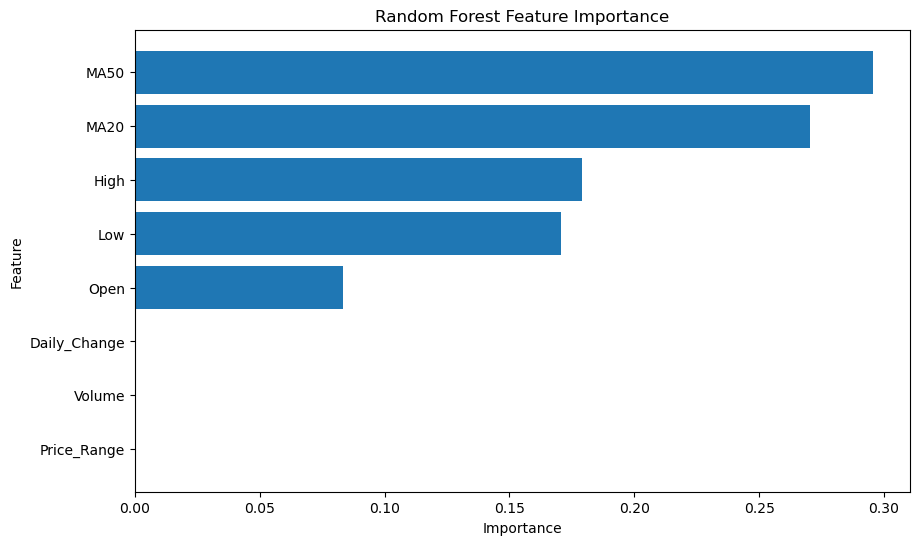

In [50]:
# Create a figure with a width of 10 inches and height of 6 inches
plt.figure(figsize=(10, 6))

# Create a horizontal bar chart showing the importance of each feature
plt.barh(
    importance["Feature"],
    importance["Importance"]
)

# Add a title and labels to the chart
plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")

# Display the most important feature at the top
plt.gca().invert_yaxis()

# Save the chart in the visualizations folder
plt.savefig("visualizations/AAPL_Feature_Importance.png")

# Show the plot
plt.show()

In [51]:
# Display the highest closing price in the dataset
print("Highest closing price:")
print(df["Close"].max())

# Display the lowest closing price in the dataset
print("\nLowest closing price:")
print(df["Close"].min())

# Calculate and display the average closing price
print("\nAverage closing price:")
print(df["Close"].mean())

# Calculate and display the average trading volume
print("\nAverage trading volume:")
print(df["Volume"].mean())

Highest closing price:
286.19000244140625

Lowest closing price:
35.54750061035156

Average closing price:
139.99539517797055

Average trading volume:
92989172.97297297


In [73]:
# Find the date when AAPL had its highest closing price
highest_date = df["Close"].idxmax()

# Find the date when AAPL had its lowest closing price
lowest_date = df["Close"].idxmin()

# Display the dates of the highest and lowest closing prices
print("Highest price date:", highest_date)
print("Lowest price date:", lowest_date)

Highest price date: 2025-12-02 00:00:00
Lowest price date: 2019-01-03 00:00:00


## Insights

Insight 1 — Price Trend

The AAPL stock price showed an overall upward trend during the selected period, although there were several fluctuations along the way. The closing price increased from a low of approximately $35.55 to a high of approximately $286.19. This indicates strong long-term growth in the stock price, along with periods of market volatility.

Insight 2 — Trading Volume

The trading volume varied considerably throughout the period, indicating changes in market activity. The average daily trading volume was approximately 94.43 million shares. Periods with higher trading volume indicate increased trading activity, while lower-volume periods indicate relatively lower market participation.

Insight 3 — Moving Average

The 20-day and 50-day moving averages were calculated to identify the broader price trend. The 50-day moving average had a slightly higher importance in the Random Forest model than the 20-day moving average. Toward the end of the dataset, the closing price was approximately $271.86, compared with a 20-day moving average of approximately $275.47 and a 50-day moving average of approximately $272.66. This shows that the recent price was slightly below both moving averages.

Insight 4 — Model Performance

Two machine learning models, Linear Regression and Random Forest, were developed and evaluated using MAE, RMSE, and R².

Model	MAE	RMSE	R²
Linear Regression	2.87	4.07	0.967
Random Forest	38.28	44.17	-2.897

Linear Regression performed significantly better than Random Forest because it had lower MAE and RMSE and a much higher R² score. Therefore, Linear Regression was selected as the better-performing model for this project.

Insight 5 — Prediction

The actual-versus-predicted visualization was used to compare the model's predicted stock prices with the actual closing prices. The Linear Regression model's predictions followed the actual prices more closely, which is consistent with its lower MAE and RMSE values and higher R² score.

Therefore, Linear Regression provided a better prediction performance on the test dataset than Random Forest.

Insight 6 — Important Features

The Random Forest feature-importance analysis showed that the 50-day moving average (MA50) was the most important feature, followed by the 20-day moving average (MA20). The High and Low prices were also important features.

The feature importance ranking was approximately:

MA50 — 29.56%
MA20 — 27.03%
High — 17.90%
Low — 17.08%
Open — 8.35%
Daily Change — 0.04%
Volume — 0.02%
Price Range — 0.02%

This indicates that the moving-average features and historical price levels contributed most to the Random Forest model's predictions.


## Conclusion 

This project analyzed historical AAPL stock market data to understand stock price movements, trading activity, trends, and patterns. The dataset was examined through data cleaning, exploratory data analysis, visualization, and feature engineering.

Several useful features were created, including the 20-day moving average, 50-day moving average, daily price change, and price range. These features were then used to develop two machine learning models: Linear Regression and Random Forest Regression.

The models were evaluated using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and R² score. Based on the evaluation results, Linear Regression performed better than Random Forest, with lower prediction errors and a higher R² score.

The analysis also showed that the moving-average features, particularly MA50 and MA20, were among the most important features in the Random Forest model. The actual-versus-predicted analysis helped compare the model's predictions with the actual stock prices.

Overall, this project demonstrates how Python, data analysis, visualization, feature engineering, and machine learning can be combined to analyze historical stock market data and develop an educational stock-price prediction model.


In [74]:
# Save the cleaned AAPL stock dataset as a CSV file
df.to_csv("dataset/AAPL_stock_data.csv")

In [75]:
# Import the os module to work with file and folder paths
import os

# Check whether the cleaned AAPL stock dataset file exists
print(os.path.exists("dataset/AAPL_stock_data.csv"))


True


In [76]:
# Create a DataFrame containing the dates, actual prices, and predicted prices
prediction_results = pd.DataFrame({
    "Date": y_test.index,
    "Actual_Price": y_test.values,
    "Predicted_Price": linear_predictions
})

# Display the first 5 prediction results
prediction_results.head()

,Date,Actual_Price,Predicted_Price
0,2024-06-06,196.889999,194.955965
1,2024-06-07,193.119995,196.464121
2,2024-06-10,207.149994,192.762447
3,2024-06-11,213.070007,205.335526
4,2024-06-12,214.240005,216.543092


In [77]:
# Save the Linear Regression prediction results as a CSV file
prediction_results.to_csv(
    "prediction_results/AAPL_linear_regression_predictions.csv",
    index=False
)

In [78]:
# Import the os module to work with file and folder paths
import os

# Check whether the Linear Regression prediction results file exists
print(os.path.exists(
    "prediction_results/AAPL_linear_regression_predictions.csv"
))

True
